In [1]:
import sys
from pathlib import Path

RACINE = Path("..").resolve()
if str(RACINE) not in sys.path:
    sys.path.insert(0, str(RACINE))

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

from src.features import CATEGORIELLES

df = pd.read_parquet("../data/processed/home_credit_features.parquet")
print(df.shape, df["TARGET"].mean().round(4))

(278232, 21) 0.0835


In [2]:
EXCLUES = ["SK_ID_CURR", "TARGET", "CODE_GENDER"]   # sexe : réservé à l'audit d'équité
CAT = CATEGORIELLES
NUM = [c for c in df.columns if c not in EXCLUES + CAT]

# 1) on met de côté 20 % pour le test
reste, test = train_test_split(df, test_size=0.20, stratify=df["TARGET"], random_state=42)
# 2) sur les 80 % restants, 25 % pour la validation (= 20 % du total)
train, val = train_test_split(reste, test_size=0.25, stratify=reste["TARGET"], random_state=42)

for nom, d in [("train", train), ("validation", val), ("test", test)]:
    print(f"{nom:10s} {len(d):>7d} lignes  taux de défaut {d['TARGET'].mean():.4f}")

X_train, y_train = train[NUM + CAT], train["TARGET"]
X_val, y_val = val[NUM + CAT], val["TARGET"]
X_test, y_test = test[NUM + CAT], test["TARGET"]

train       166938 lignes  taux de défaut 0.0835
validation   55647 lignes  taux de défaut 0.0835
test         55647 lignes  taux de défaut 0.0835


In [3]:
def evaluer(nom, modele, X, y):
    p = modele.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, p)
    res = {"modele": nom,
           "AUC": round(roc_auc_score(y, p), 4),
           "PR-AUC": round(average_precision_score(y, p), 4),
           "KS": round((tpr - fpr).max(), 4)}
    print(res)
    return res

pretraitement = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), NUM),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
])

reglog = Pipeline([("prep", pretraitement),
                   ("clf", LogisticRegression(max_iter=1000))])
reglog.fit(X_train, y_train)

resultats = [evaluer("Régression logistique", reglog, X_val, y_val)]

{'modele': 'Régression logistique', 'AUC': 0.6401, 'PR-AUC': 0.1401, 'KS': np.float64(0.2146)}


# Modèle de référence : régression logistique

## 1. Protocole

**Séparation des données.** Le jeu Home Credit nettoyé (278 232 dossiers) est divisé de façon stratifiée sur la cible en trois échantillons, avec une graine fixe (`random_state = 42`) pour garantir la reproductibilité.

| Échantillon | Dossiers | Taux de défaut | Rôle |
|---|---|---|---|
| Apprentissage | 166 938 (60 %) | 8,35 % | ajustement des modèles |
| Validation | 55 647 (20 %) | 8,35 % | comparaison des modèles, réglage, calibration |
| Test | 55 647 (20 %) | 8,35 % | mesure finale, utilisée une seule fois |

La stratification conserve exactement le même taux de défaut dans les trois échantillons. Le jeu de test n'intervient dans aucun choix de conception : il sert uniquement à mesurer la performance du modèle retenu.

**Variables.** Le modèle utilise les variables numériques (âge, ancienneté, revenu, montant du crédit, annuité, nombre d'enfants, taille de la famille, indicateur `sans_emploi`, ratios `credit_sur_revenu`, `annuite_sur_revenu`, `duree_implicite`) et les variables catégorielles (type de revenu, éducation, situation familiale, logement, profession, propriété d'un bien immobilier, propriété d'un véhicule). Le sexe, les scores externes (`EXT_SOURCE_*`) et les identifiants sont exclus.

**Prétraitement (dans un pipeline).** Imputation des valeurs numériques manquantes par la médiane, standardisation des variables numériques, encodage *one-hot* des variables catégorielles. Tous ces paramètres sont estimés **sur l'échantillon d'apprentissage uniquement** puis appliqués à la validation et au test, afin d'éviter toute fuite d'information.

**Choix de ne pas pondérer les classes.** Aucune pondération (`class_weight`) n'est appliquée. L'application doit annoncer des probabilités de remboursement interprétables (par exemple « 96 % de chances de remboursement ») : une pondération gonflerait artificiellement les probabilités de défaut. Le déséquilibre des classes est traité par le choix des métriques.

## 2. Métriques

- **AUC-ROC** : probabilité que le modèle attribue un risque plus élevé à un client défaillant qu'à un bon payeur. Le hasard donne 0,50.
- **PR-AUC** (aire sous la courbe précision-rappel) : adaptée aux classes rares. Le hasard donne le taux de défaut, soit 0,0835.
- **KS** (Kolmogorov-Smirnov) : écart maximal entre les distributions cumulées des bons et des mauvais payeurs ; indicateur courant en scoring bancaire.

## 3. Résultats sur l'échantillon de validation

| Modèle | AUC | PR-AUC | KS |
|---|---|---|---|
| Régression logistique | 0,6401 | 0,1401 | 0,2146 |

## 4. Interprétation

- Avec une AUC de 0,64, le modèle classe correctement un couple (défaillant, bon payeur) dans 64 % des cas, contre 50 % pour le hasard. Le pouvoir discriminant existe mais reste modeste.
- La PR-AUC de 0,14 représente environ **1,7 fois** le niveau du hasard (0,0835) : le modèle concentre mieux les défaillants dans les scores élevés qu'un tirage aléatoire.
- Le KS de 0,21 confirme une séparation réelle mais limitée entre les deux populations.
- Ces valeurs sont cohérentes avec la nature du jeu de données. Les meilleures solutions publiées sur Home Credit exploitent les scores externes `EXT_SOURCE_*` et les historiques de crédit d'autres fichiers. Ces informations n'existent pas dans le contexte d'une IMF sénégalaise, elles ont donc été écartées volontairement. La performance obtenue correspond à ce qui est réellement transposable.
- Les signaux les plus informatifs identifiés dans l'analyse exploratoire (âge, ancienneté, type de revenu, niveau d'éducation) sont de nature **linéaire ou monotone**, ce qui explique que le modèle linéaire capte déjà l'essentiel de l'information disponible.

## 5. Limites

- Le modèle linéaire ne représente pas les interactions entre variables (par exemple l'effet conjoint de l'âge et de l'ancienneté).
- Les relations non monotones observées pour `credit_sur_revenu` et `duree_implicite` (voir l'analyse exploratoire) sont mal représentées par un coefficient unique. Elles résultent d'un biais de sélection, non d'un effet causal.
- Les probabilités n'ont pas encore été calibrées : leur fiabilité sera vérifiée dans une étape dédiée.

## 6. Rôle dans la suite

- Le Random Forest améliore l'AUC de 0,025 (0,6401 → 0,6652) : il existe donc des **interactions et des effets non linéaires** que le modèle linéaire ne capte pas, mais ils restent de faible ampleur. Les signaux dominants (âge, ancienneté, type de revenu, éducation) sont bien captés par la régression.

In [4]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

foret = Pipeline([
    ("prep", clone(pretraitement)),
    ("clf", RandomForestClassifier(
        n_estimators=300, min_samples_leaf=50,
        n_jobs=-1, random_state=42)),
])
foret.fit(X_train, y_train)

resultats.append(evaluer("Random Forest", foret, X_val, y_val))

{'modele': 'Random Forest', 'AUC': 0.6652, 'PR-AUC': 0.1536, 'KS': np.float64(0.2468)}


# Random Forest

## Paramétrage
300 arbres, au moins 50 dossiers par feuille (`min_samples_leaf = 50`), même prétraitement que la régression logistique, sans pondération des classes. Le seuil de 50 dossiers par feuille évite les probabilités extrêmes (0 % ou 100 %) que produiraient des feuilles trop petites sur une classe rare.

## Résultats sur l'échantillon de validation

| Modèle | AUC | PR-AUC | KS |
|---|---|---|---|
| Régression logistique | 0,6401 | 0,1401 | 0,2146 |
| Random Forest | 0,6652 | 0,1536 | 0,2468 |

## Interprétation
- Le Random Forest améliore les trois métriques : +0,025 d'AUC, +0,013 de PR-AUC, +0,032 de KS. Ce gain traduit la présence d'interactions et d'effets non linéaires que le modèle linéaire ne représente pas.
- L'amélioration reste modeste. Les variables disponibles (sans scores externes ni historique de crédit) limitent le plafond de performance, quel que soit le modèle.
- Le Random Forest est moins lisible qu'une régression, et il ne permet pas d'imposer de contrainte de monotonie. Or la suggestion de montant exige qu'une réduction du montant ne puisse pas augmenter le risque estimé. C'est une raison de privilégier XGBoost, qui accepte ces contraintes.

In [5]:
from xgboost import XGBClassifier

# Noms des colonnes après prétraitement, pour placer les contraintes au bon endroit
prep_tmp = clone(pretraitement).fit(X_train)
noms = prep_tmp.get_feature_names_out()
CROISSANTES = ("num__credit_sur_revenu", "num__annuite_sur_revenu")
contraintes = tuple(1 if n in CROISSANTES else 0 for n in noms)
print(len(noms), "colonnes ;", sum(contraintes), "contraintes croissantes")

xgb = Pipeline([
    ("prep", clone(pretraitement)),
    ("clf", XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=3,
        subsample=0.8, colsample_bytree=0.8,
        monotone_constraints=contraintes,
        tree_method="hist", n_jobs=-1, random_state=42)),
])
xgb.fit(X_train, y_train)

resultats.append(evaluer("XGBoost (monotone)", xgb, X_val, y_val))

55 colonnes ; 2 contraintes croissantes
{'modele': 'XGBoost (monotone)', 'AUC': 0.6842, 'PR-AUC': 0.1693, 'KS': np.float64(0.2705)}


In [6]:
xgb_libre = Pipeline([
    ("prep", clone(pretraitement)),
    ("clf", XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=3,
        subsample=0.8, colsample_bytree=0.8,
        tree_method="hist", n_jobs=-1, random_state=42)),
])
xgb_libre.fit(X_train, y_train)

resultats.append(evaluer("XGBoost (libre)", xgb_libre, X_val, y_val))
pd.DataFrame(resultats)

{'modele': 'XGBoost (libre)', 'AUC': 0.6842, 'PR-AUC': 0.1695, 'KS': np.float64(0.2696)}


,modele,AUC,PR-AUC,KS
0,Régression logistique,0.6401,0.1401,0.2146
1,Random Forest,0.6652,0.1536,0.2468
2,XGBoost (monotone),0.6842,0.1693,0.2705
3,XGBoost (libre),0.6842,0.1695,0.2696


# XGBoost avec contraintes de monotonie

## Paramétrage
300 arbres de profondeur maximale 3, taux d'apprentissage 0,05, sous-échantillonnage de 80 % des dossiers et de 80 % des variables à chaque arbre, même prétraitement que les modèles précédents, sans pondération des classes.

**Contraintes de monotonie.** Sur les 55 colonnes issues du prétraitement, deux reçoivent une contrainte croissante : `credit_sur_revenu` et `annuite_sur_revenu`. Le risque de défaut estimé ne peut donc que croître (ou rester constant) lorsque l'une de ces deux variables augmente, les autres restant fixes. Cette propriété est indispensable à la suggestion de montant : réduire le montant demandé, à durée constante, diminue le crédit et l'annuité rapportés au revenu, et ne peut donc pas augmenter le risque estimé.

La contrainte impose une relation que les données contredisent en partie (relation en cloche de `credit_sur_revenu`, due au biais de sélection). Elle protège ainsi le modèle d'un artefact de sélection qui conduirait à recommander d'augmenter le montant.

## Résultats sur l'échantillon de validation

| Modèle | AUC | PR-AUC | KS |
|---|---|---|---|
| Régression logistique | 0,6401 | 0,1401 | 0,2146 |
| Random Forest | 0,6652 | 0,1536 | 0,2468 |
| XGBoost (monotone) | 0,6842 | 0,1693 | 0,2705 |

## Interprétation
- XGBoost obtient les meilleurs résultats sur les trois métriques, y compris sous contraintes : +0,019 d'AUC par rapport au Random Forest et +0,044 par rapport à la régression logistique.
- Le gain de PR-AUC porte le modèle à environ 2 fois la performance du hasard (0,1693 contre 0,0835).
- La performance absolue reste limitée par l'information disponible (absence de scores externes et d'historique de crédit), dans l'ensemble des trois modèles.
- Ces résultats sont obtenus sans optimisation fine des hyperparamètres.

## Choix retenu
XGBoost avec contraintes de monotonie est le **modèle candidat** : il est le plus performant et le seul à garantir la cohérence exigée par la suggestion de montant.
## Coût de la contrainte de monotonie

| Modèle | AUC | PR-AUC | KS |
|---|---|---|---|
| XGBoost (libre) | 0,6842 | 0,1695 | 0,2696 |
| XGBoost (monotone) | 0,6842 | 0,1693 | 0,2705 |

L'AUC est identique et les écarts de PR-AUC (0,0002) et de KS (0,0009) sont négligeables. La contrainte de monotonie n'entraîne donc aucune perte mesurable de performance : la cohérence exigée par la suggestion de montant est obtenue sans compromis.

In [7]:
from sklearn.metrics import brier_score_loss, log_loss

p_val = xgb.predict_proba(X_val)[:, 1]
print("Brier   :", round(brier_score_loss(y_val, p_val), 5))
print("Logloss :", round(log_loss(y_val, p_val), 5))
print("Référence (prédire toujours le taux moyen) :",
      round(brier_score_loss(y_val, np.full(len(y_val), y_train.mean())), 5))

fiab = (pd.DataFrame({"prevu": p_val, "reel": y_val.values})
          .groupby(pd.qcut(p_val, 10, duplicates="drop"), observed=True)
          .agg(prevu=("prevu", "mean"), reel=("reel", "mean"), n=("reel", "size"))
          .round(4))
print(fiab.to_string())

Brier   : 0.07355
Logloss : 0.27022
Référence (prédire toujours le taux moyen) : 0.07649
                   prevu    reel     n
(0.00302, 0.035]  0.0254  0.0259  5565
(0.035, 0.0456]   0.0406  0.0397  5565
(0.0456, 0.0533]  0.0496  0.0433  5564
(0.0533, 0.0606]  0.0569  0.0523  5565
(0.0606, 0.069]   0.0646  0.0570  5565
(0.069, 0.0803]   0.0743  0.0780  5564
(0.0803, 0.096]   0.0876  0.0839  5565
(0.096, 0.118]    0.1061  0.1037  5564
(0.118, 0.155]    0.1346  0.1425  5565
(0.155, 0.425]    0.1974  0.2083  5565


# Calibration des probabilités

Les probabilités de défaut du modèle XGBoost sont comparées, par décile de score, au taux de défaut réellement observé sur l'échantillon de validation.

| Décile | Prévu | Observé |
|---|---|---|
| 1 | 2,54 % | 2,59 % |
| 2 | 4,06 % | 3,97 % |
| 3 | 4,96 % | 4,33 % |
| 4 | 5,69 % | 5,23 % |
| 5 | 6,46 % | 5,70 % |
| 6 | 7,43 % | 7,80 % |
| 7 | 8,76 % | 8,39 % |
| 8 | 10,61 % | 10,37 % |
| 9 | 13,46 % | 14,25 % |
| 10 | 19,74 % | 20,83 % |

Le score de Brier est de 0,0736 contre 0,0765 pour un modèle qui prédirait toujours le taux moyen de défaut (gain de 3,8 %).

**Conclusion.** Les probabilités sont bien calibrées (écart maximal d'environ un point dans le décile le plus risqué, sans biais systématique). Aucune correction supplémentaire n'est appliquée : le modèle est entraîné avec une perte logistique et sans pondération des classes, ce qui préserve l'interprétation des probabilités.

**Remarque.** Les scores produits s'étendent de 0,3 % à 42,5 % de probabilité de défaut. Les seuils de décision (acceptation, refus, suggestion d'un montant inférieur) sont des règles de politique de crédit de l'institution, paramétrables, et non des propriétés du modèle.

In [8]:
prep_opt = clone(pretraitement).fit(X_train)
Xtr = prep_opt.transform(X_train)
Xva = prep_opt.transform(X_val)

essais = []
for profondeur in [2, 3, 4, 5]:
    for poids_min in [10, 50]:
        m = XGBClassifier(
            n_estimators=1000, learning_rate=0.03, max_depth=profondeur,
            min_child_weight=poids_min, subsample=0.8, colsample_bytree=0.8,
            monotone_constraints=contraintes, tree_method="hist",
            eval_metric="auc", early_stopping_rounds=50,
            n_jobs=-1, random_state=42)
        m.fit(Xtr, y_train, eval_set=[(Xva, y_val)], verbose=False)
        essais.append({"profondeur": profondeur, "poids_min": poids_min,
                       "arbres": m.best_iteration + 1,
                       "AUC_val": round(m.best_score, 4)})

pd.DataFrame(essais).sort_values("AUC_val", ascending=False)

,profondeur,poids_min,arbres,AUC_val
6,5,10,965,0.6949
7,5,50,1000,0.6942
4,4,10,993,0.6941
5,4,50,998,0.6936
2,3,10,999,0.6914
3,3,50,1000,0.6912
1,2,50,1000,0.6840
0,2,10,999,0.6839


In [9]:
from sklearn.metrics import roc_auc_score

essais2 = []
for profondeur in [5, 6, 7]:
    m = XGBClassifier(
        n_estimators=2000, learning_rate=0.05, max_depth=profondeur,
        min_child_weight=10, subsample=0.8, colsample_bytree=0.8,
        monotone_constraints=contraintes, tree_method="hist",
        eval_metric="auc", early_stopping_rounds=50,
        n_jobs=-1, random_state=42)
    m.fit(Xtr, y_train, eval_set=[(Xva, y_val)], verbose=False)
    essais2.append({
        "profondeur": profondeur,
        "arbres": m.best_iteration + 1,
        "AUC_train": round(roc_auc_score(y_train, m.predict_proba(Xtr)[:, 1]), 4),
        "AUC_val": round(m.best_score, 4)})

pd.DataFrame(essais2)

,profondeur,arbres,AUC_train,AUC_val
0,5,517,0.7603,0.6942
1,6,360,0.7700,0.6930
2,7,240,0.7748,0.6922


# Réglage des hyperparamètres de XGBoost

## Méthode
Les hyperparamètres sont choisis sur l'**échantillon de validation** (jamais sur le test). Un arrêt automatique interrompt l'entraînement dès que l'AUC de validation ne progresse plus pendant 50 arbres, ce qui fixe le nombre d'arbres. Les contraintes de monotonie sont conservées.

## Premier tour (taux d'apprentissage 0,03, 1000 arbres maximum)

| Profondeur | `min_child_weight` | AUC validation |
|---|---|---|
| 5 | 10 | 0,6949 |
| 5 | 50 | 0,6942 |
| 4 | 10 | 0,6941 |
| 4 | 50 | 0,6936 |
| 3 | 10 | 0,6914 |
| 3 | 50 | 0,6912 |
| 2 | 50 | 0,6840 |
| 2 | 10 | 0,6839 |

La profondeur est l'hyperparamètre déterminant : passer de 2 à 5 gagne 0,011 d'AUC, ce qui traduit la présence d'interactions entre variables. Le poids minimal par feuille a un effet négligeable (au plus 0,0007).

## Second tour (taux d'apprentissage 0,05, 2000 arbres maximum)

| Profondeur | Arbres | AUC apprentissage | AUC validation |
|---|---|---|---|
| 5 | 517 | 0,7603 | 0,6942 |
| 6 | 360 | 0,7700 | 0,6930 |
| 7 | 240 | 0,7748 | 0,6922 |

Au-delà de la profondeur 5, l'AUC d'apprentissage continue de croître alors que celle de validation décroît : le modèle commence à mémoriser le bruit (surapprentissage). Le réglage s'arrête donc à ce palier.

## Configuration retenue
Profondeur maximale 5 ; poids minimal par feuille 10 ; taux d'apprentissage 0,03 ; 965 arbres ; sous-échantillonnage de 80 % des dossiers et de 80 % des variables par arbre ; contraintes de monotonie croissantes sur `credit_sur_revenu` et `annuite_sur_revenu`.
Le réglage améliore l'AUC de validation de 0,6842 à 0,6949 (+0,011).

In [10]:
import joblib

MODELE_PARAMS = dict(
    n_estimators=965, learning_rate=0.03, max_depth=5, min_child_weight=10,
    subsample=0.8, colsample_bytree=0.8,
    monotone_constraints=contraintes, tree_method="hist",
    n_jobs=-1, random_state=42)

modele_final = Pipeline([
    ("prep", clone(pretraitement)),
    ("clf", XGBClassifier(**MODELE_PARAMS)),
])
modele_final.fit(X_train, y_train)
resultats.append(evaluer("XGBoost final (monotone)", modele_final, X_val, y_val))

Path("../models").mkdir(exist_ok=True)
joblib.dump(modele_final, "../models/xgb_home_credit_v1.joblib")

{'modele': 'XGBoost final (monotone)', 'AUC': 0.6949, 'PR-AUC': 0.1761, 'KS': np.float64(0.2966)}


['../models/xgb_home_credit_v1.joblib']

In [11]:
res_test = [
    evaluer("Régression logistique", reglog, X_test, y_test),
    evaluer("Random Forest", foret, X_test, y_test),
    evaluer("XGBoost final (monotone)", modele_final, X_test, y_test),
]

p_test = modele_final.predict_proba(X_test)[:, 1]
print("Brier test :", round(brier_score_loss(y_test, p_test), 5))
fiab_t = (pd.DataFrame({"prevu": p_test, "reel": y_test.values})
            .groupby(pd.qcut(p_test, 10, duplicates="drop"), observed=True)
            .agg(prevu=("prevu", "mean"), reel=("reel", "mean"), n=("reel", "size"))
            .round(4))
print(fiab_t.to_string())

{'modele': 'Régression logistique', 'AUC': 0.6426, 'PR-AUC': 0.1411, 'KS': np.float64(0.2159)}
{'modele': 'Random Forest', 'AUC': 0.673, 'PR-AUC': 0.1611, 'KS': np.float64(0.2586)}
{'modele': 'XGBoost final (monotone)', 'AUC': 0.7026, 'PR-AUC': 0.1789, 'KS': np.float64(0.303)}
Brier test : 0.07302
                    prevu    reel     n
(0.00232, 0.0272]  0.0193  0.0234  5566
(0.0272, 0.038]    0.0327  0.0307  5564
(0.038, 0.047]     0.0425  0.0374  5564
(0.047, 0.056]     0.0515  0.0453  5565
(0.056, 0.0659]    0.0608  0.0645  5565
(0.0659, 0.0783]   0.0718  0.0715  5564
(0.0783, 0.0953]   0.0864  0.0855  5565
(0.0953, 0.121]    0.1070  0.1148  5564
(0.121, 0.165]     0.1398  0.1418  5565
(0.165, 0.51]      0.2210  0.2196  5565


# Évaluation finale sur l'échantillon de test

Le test (55 647 dossiers, jamais utilisé pour les choix de conception) est évalué une seule fois, après le choix du modèle sur la validation.

| Modèle | AUC | PR-AUC | KS |
|---|---|---|---|
| Régression logistique | 0,6426 | 0,1411 | 0,2159 |
| Random Forest | 0,6730 | 0,1611 | 0,2586 |
| **XGBoost (monotone, réglé)** | **0,7026** | **0,1789** | **0,3030** |

## Interprétation
- Le classement observé en validation est confirmé : XGBoost surpasse le Random Forest (+0,030 d'AUC) et la régression logistique (+0,060).
- L'AUC du modèle final sur le test (0,7026) est cohérente avec celle de la validation (0,6949) : le réglage des hyperparamètres n'a pas induit de surapprentissage de l'échantillon de validation.
- Le PR-AUC de 0,179 représente environ 2,1 fois le niveau du hasard (0,0835).
- Cette performance est obtenue **sans les scores externes ni l'historique de crédit**, indisponibles dans le contexte sénégalais. Elle correspond à une information réellement mobilisable par une IMF.

## Calibration sur le test

| Décile | Prévu | Observé |
|---|---|---|
| 1 | 1,93 % | 2,34 % |
| 2 | 3,27 % | 3,07 % |
| 3 | 4,25 % | 3,74 % |
| 4 | 5,15 % | 4,53 % |
| 5 | 6,08 % | 6,45 % |
| 6 | 7,18 % | 7,15 % |
| 7 | 8,64 % | 8,55 % |
| 8 | 10,70 % | 11,48 % |
| 9 | 13,98 % | 14,18 % |
| 10 | 22,10 % | 21,96 % |

Le score de Brier est de 0,0730 contre 0,0765 pour la référence (gain de 4,6 %). Les probabilités sont bien calibrées sur des données non vues : l'écart maximal par décile est d'environ 0,6 point. Les scores s'étendent d'environ 0,2 % à 50 % de probabilité de défaut.

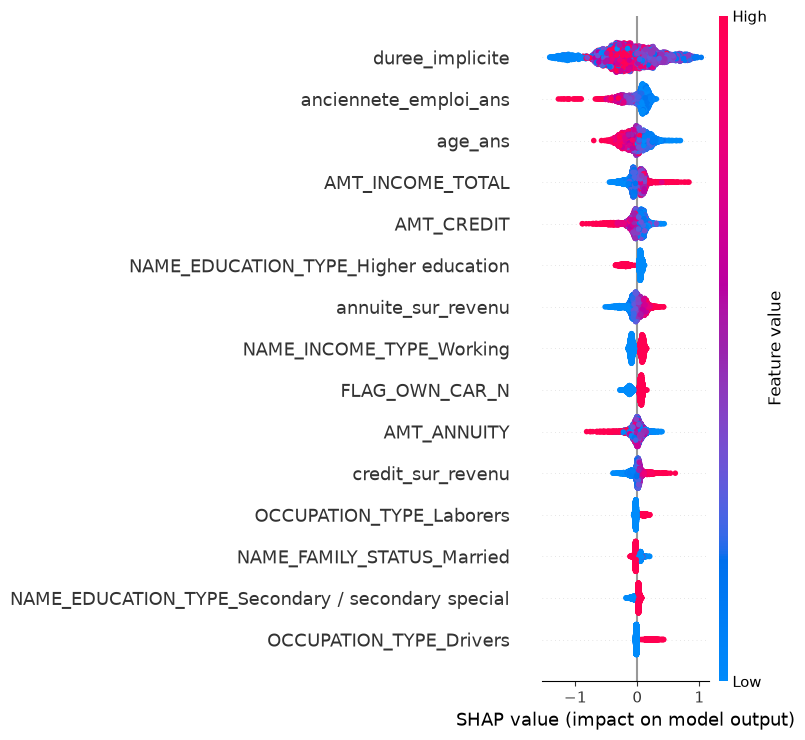

In [12]:
import shap
import matplotlib.pyplot as plt

prep_f = modele_final.named_steps["prep"]
clf_f = modele_final.named_steps["clf"]
noms_f = [n.split("__", 1)[1] for n in prep_f.get_feature_names_out()]

echantillon = X_val.sample(5000, random_state=42)
Xs = prep_f.transform(echantillon)
if hasattr(Xs, "toarray"):
    Xs = Xs.toarray()

explicateur = shap.TreeExplainer(clf_f)
valeurs = explicateur.shap_values(Xs)

shap.summary_plot(valeurs, Xs, feature_names=noms_f, max_display=15, show=False)
plt.tight_layout()
plt.savefig("../docs/figures/shap_resume.png", dpi=200, bbox_inches="tight")
plt.show()

In [13]:
MONTANTS_BRUTS = ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY"]
NUM2 = [c for c in NUM if c not in MONTANTS_BRUTS]
print("Numériques v2 :", NUM2)

pretraitement2 = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), NUM2),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
])

noms2 = clone(pretraitement2).fit(X_train[NUM2 + CAT]).get_feature_names_out()
contraintes2 = tuple(1 if n in CROISSANTES else 0 for n in noms2)
print(len(noms2), "colonnes ;", sum(contraintes2), "contraintes croissantes")

modele_v2 = Pipeline([
    ("prep", pretraitement2),
    ("clf", XGBClassifier(**{**MODELE_PARAMS, "monotone_constraints": contraintes2})),
])
modele_v2.fit(X_train[NUM2 + CAT], y_train)

resultats.append(evaluer("XGBoost v2 (sans montants bruts)", modele_v2, X_val[NUM2 + CAT], y_val))

Numériques v2 : ['CNT_CHILDREN', 'CNT_FAM_MEMBERS', 'age_ans', 'anciennete_emploi_ans', 'sans_emploi', 'credit_sur_revenu', 'annuite_sur_revenu', 'duree_implicite']
52 colonnes ; 2 contraintes croissantes
{'modele': 'XGBoost v2 (sans montants bruts)', 'AUC': 0.6917, 'PR-AUC': 0.1743, 'KS': np.float64(0.283)}


In [14]:
joblib.dump(modele_v2, "../models/xgb_home_credit_v2.joblib")

res_test_v2 = evaluer("XGBoost v2 (test)", modele_v2, X_test[NUM2 + CAT], y_test)

p_t2 = modele_v2.predict_proba(X_test[NUM2 + CAT])[:, 1]
print("Brier test :", round(brier_score_loss(y_test, p_t2), 5))
print("Score min / max :", round(p_t2.min(), 4), "/", round(p_t2.max(), 4))
fiab2 = (pd.DataFrame({"prevu": p_t2, "reel": y_test.values})
           .groupby(pd.qcut(p_t2, 10, duplicates="drop"), observed=True)
           .agg(prevu=("prevu", "mean"), reel=("reel", "mean"), n=("reel", "size"))
           .round(4))
print(fiab2.to_string())

{'modele': 'XGBoost v2 (test)', 'AUC': 0.6976, 'PR-AUC': 0.1775, 'KS': np.float64(0.2958)}
Brier test : 0.07315
Score min / max : 0.003 / 0.5509
                    prevu    reel     n
(0.00202, 0.0266]  0.0191  0.0241  5565
(0.0266, 0.0374]   0.0321  0.0314  5565
(0.0374, 0.0468]   0.0422  0.0399  5564
(0.0468, 0.0557]   0.0512  0.0501  5565
(0.0557, 0.0655]   0.0604  0.0622  5565
(0.0655, 0.0783]   0.0717  0.0699  5564
(0.0783, 0.0954]   0.0862  0.0872  5565
(0.0954, 0.121]    0.1073  0.1098  5564
(0.121, 0.166]     0.1409  0.1418  5565
(0.166, 0.551]     0.2215  0.2181  5565


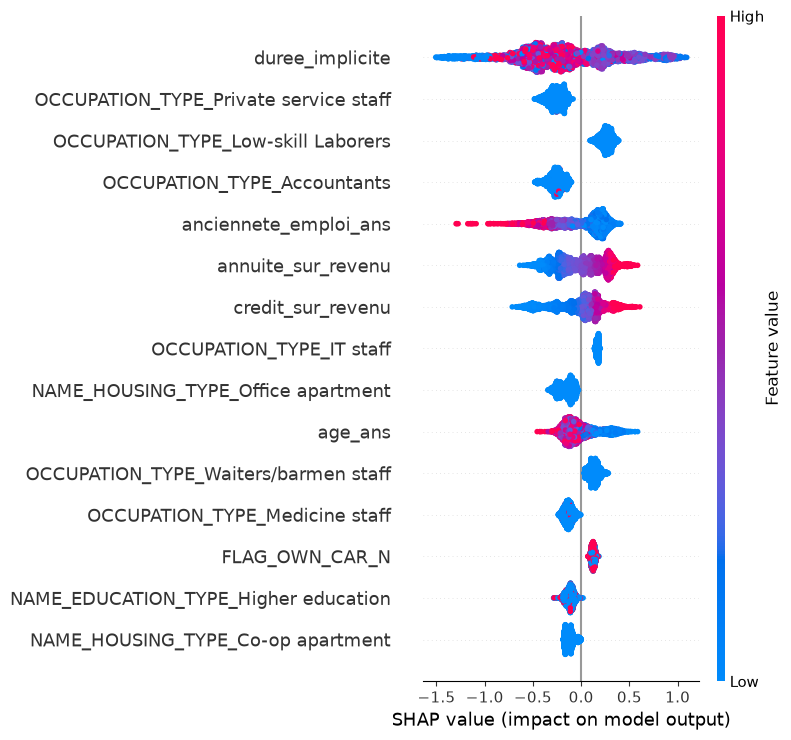

In [15]:
prep2 = modele_v2.named_steps["prep"]
clf2 = modele_v2.named_steps["clf"]
noms_v2 = [n.split("__", 1)[1] for n in prep2.get_feature_names_out()]

ech = X_val[NUM2 + CAT].sample(5000, random_state=42)
Xs2 = prep2.transform(ech)
if hasattr(Xs2, "toarray"):
    Xs2 = Xs2.toarray()

val_shap = shap.TreeExplainer(clf2).shap_values(Xs2)

shap.summary_plot(val_shap, Xs2, feature_names=noms_v2, max_display=15, show=False)
plt.tight_layout()
plt.savefig("../docs/figures/shap_resume_v2.png", dpi=200, bbox_inches="tight")
plt.show()

# Modèle final : XGBoost v2 (sans montants bruts)

## Correction de la liste des variables
La première version du modèle XGBoost incluait les montants bruts (`AMT_INCOME_TOTAL`, `AMT_CREDIT`, `AMT_ANNUITY`). L'analyse SHAP a montré deux défauts : ces montants sont redondants avec les ratios (leurs effets individuels se compensent et ne sont pas interprétables), et ils sont exprimés dans la monnaie du jeu d'origine, donc non transposables au FCFA. La version 2 n'utilise que des variables **sans unité monétaire** : ratios `credit_sur_revenu`, `annuite_sur_revenu`, `duree_implicite`, âge, ancienneté, indicateur `sans_emploi`, composition du ménage et variables catégorielles (52 colonnes après encodage).

Ce choix a été arrêté sur l'échantillon de validation (AUC 0,6917 contre 0,6949, soit une perte de 0,003). Le jeu de test a ainsi été consulté deux fois (modèle v1 puis v2) ; le choix de la v2 repose sur la validation et non sur le test.

## Résultats sur l'échantillon de test

| Mesure | Valeur |
|---|---|
| AUC | 0,6976 |
| PR-AUC | 0,1775 |
| KS | 0,2958 |
| Brier | 0,0731 (référence : 0,0765) |
| Scores de défaut | de 0,3 % à 55 % |

La calibration est très bonne : dans le décile le plus risqué, 22,2 % de défauts prévus pour 21,8 % observés, et l'écart reste inférieur à 0,6 point dans tous les déciles.

## Explicabilité (valeurs de Shapley)
- **Endettement** : des valeurs élevées de `annuite_sur_revenu` et `credit_sur_revenu` augmentent le risque, conformément à la contrainte de monotonie.
- **Stabilité** : une ancienneté et un âge élevés réduisent le risque ; l'ancienneté produit les effets individuels les plus forts (jusqu'à −1,4 en log-cotes).
- **Profession** : les professions peu qualifiées et les serveurs/barmen augmentent le risque, les comptables, le personnel des services privés et le personnel médical le diminuent.
- **Durée implicite** : variable la plus influente, avec un effet non monotone. Cette relation est influencée par le biais de sélection du jeu d'origine (voir l'analyse exploratoire) et par le fait qu'elle reflète le type de produit de crédit.

## Limites
1. Les catégories professionnelles du jeu d'origine ne correspondent pas au secteur informel sénégalais : une adaptation sera nécessaire pour le déploiement.
2. Les professions peuvent servir de variable de substitution au sexe, exclu du modèle : un audit d'équité est mené sur l'échantillon de test.
3. En exploitation, la durée du crédit est une donnée saisie par l'agent. La suggestion de montant la maintient donc constante.

In [16]:
from src.suggestion import suggerer_montant, probabilite_defaut

COLONNES = NUM2 + CAT
RATIOS = ["credit_sur_revenu", "annuite_sur_revenu", "duree_implicite"]
COLS_PROFIL = [c for c in COLONNES if c not in RATIOS]

p_test_v2 = modele_v2.predict_proba(X_test[COLONNES])[:, 1]
candidats = test[(p_test_v2 > 0.25) & (p_test_v2 < 0.35)].head(3)

for _, c in candidats.iterrows():
    profil = c[COLS_PROFIL].to_dict()
    res = suggerer_montant(
        modele_v2, profil,
        montant_demande=c["AMT_CREDIT"], duree=c["duree_implicite"],
        revenu=c["AMT_INCOME_TOTAL"], colonnes=COLONNES, pas=10_000, montant_min=10_000)
    print(f"Demandé {c['AMT_CREDIT']:>10,.0f} | p={res['p_demande']:.3f} -> {res['decision']}, "
          f"montant {res['montant']}, p={res['p_defaut']}")

Demandé    640,080 | p=0.347 -> refus, montant None, p=None
Demandé    152,820 | p=0.258 -> accord_reduit, montant 52820.0, p=0.12438671290874481
Demandé    254,700 | p=0.288 -> refus, montant None, p=None


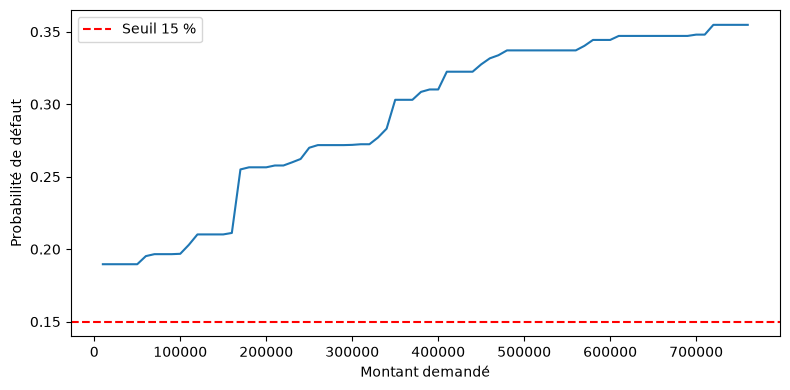

Courbe croissante : True


In [17]:
c = candidats.iloc[0]
profil = c[COLS_PROFIL].to_dict()
montants = np.arange(10_000, c["AMT_CREDIT"] * 1.2, 10_000)
probas = [probabilite_defaut(modele_v2, profil, m, c["duree_implicite"],
                             c["AMT_INCOME_TOTAL"], COLONNES) for m in montants]

plt.figure(figsize=(8, 4))
plt.plot(montants, probas)
plt.axhline(0.15, color="red", linestyle="--", label="Seuil 15 %")
plt.xlabel("Montant demandé")
plt.ylabel("Probabilité de défaut")
plt.legend()
plt.tight_layout()
plt.savefig("../docs/figures/courbe_risque_montant.png", dpi=200)
plt.show()
print("Courbe croissante :", all(np.diff(probas) >= -1e-9))

In [21]:
a_risque = test[p_test_v2 > 0.15].sample(300, random_state=42)

decisions = []
for _, c in a_risque.iterrows():
    res = suggerer_montant(
        modele_v2, c[COLS_PROFIL].to_dict(),
        montant_demande=c["AMT_CREDIT"], duree=c["duree_implicite"],
        revenu=c["AMT_INCOME_TOTAL"], colonnes=COLONNES, pas=10_000, montant_min=10_000)
    res["ratio"] = res["montant"] / c["AMT_CREDIT"] if res["montant"] else np.nan
    decisions.append(res)

d = pd.DataFrame(decisions)
print(d["decision"].value_counts(normalize=True).round(3))
print("Montant suggéré / montant demandé (médiane) :", round(d["ratio"].median(), 2))

decision
accord_reduit    0.66
refus            0.34
Name: proportion, dtype: float64
Montant suggéré / montant demandé (médiane) : 0.49


In [20]:
acc = d[d["decision"] == "accord_reduit"]["ratio"]
print(acc.describe(percentiles=[.1, .25, .5, .75, .9]).round(2))
print("Part des réductions à moins de 25 % du montant demandé :", round((acc < 0.25).mean(), 3))

count    198.00
mean       0.52
std        0.25
min        0.09
10%        0.20
25%        0.30
50%        0.49
75%        0.73
90%        0.86
max        0.99
Name: ratio, dtype: float64
Part des réductions à moins de 25 % du montant demandé : 0.177


In [23]:
import importlib
import src.suggestion
importlib.reload(src.suggestion)
from src.suggestion import suggerer_montant
import inspect
print(inspect.signature(suggerer_montant))

(modele, profil, montant_demande, duree, revenu, colonnes, seuil=0.15, pas=50000, montant_min=50000, ratio_min=0.5)


In [24]:
a_risque = test[p_test_v2 > 0.15].sample(300, random_state=42)

decisions = []
for _, c in a_risque.iterrows():
    res = suggerer_montant(
        modele_v2, c[COLS_PROFIL].to_dict(),
        montant_demande=c["AMT_CREDIT"], duree=c["duree_implicite"],
        revenu=c["AMT_INCOME_TOTAL"], colonnes=COLONNES, pas=10_000, montant_min=10_000)
    res["ratio"] = res["montant"] / c["AMT_CREDIT"] if res["montant"] else np.nan
    decisions.append(res)

d = pd.DataFrame(decisions)
print(d["decision"].value_counts(normalize=True).round(3))
print("Montant suggéré / montant demandé (médiane) :", round(d["ratio"].median(), 2))
print("Ratio minimal observé :", round(d["ratio"].min(), 2))

decision
refus            0.673
accord_reduit    0.327
Name: proportion, dtype: float64
Montant suggéré / montant demandé (médiane) : 0.73
Ratio minimal observé : 0.5


## Évaluation sur 300 dossiers du test dont le risque dépasse le seuil de 15 %

Une première version de la recherche, avec un plancher de 10 000, acceptait un montant réduit pour 66 % des dossiers. La distribution de ces réductions montrait cependant que 17,7 % d'entre elles ramenaient le montant sous 25 % de la demande (médiane : 49 % de la demande ; écart interquartile : 30 % à 73 %). Une proposition aussi éloignée du besoin du client équivaut à un refus.

## Règle de réduction maximale
Un paramètre de politique `ratio_min` (50 % par défaut) interdit de proposer moins de la moitié du montant demandé. En dessous, le dossier est refusé. Résultats avec cette règle :

| Issue | Part |
|---|---|
| Accord avec montant réduit | 32,7 % |
| Refus | 67,3 % |

Pour les dossiers récupérés, le montant suggéré représente en médiane 73 % du montant demandé (minimum 50 %, par construction).

**Lecture.** Environ un dossier à risque sur trois peut être accordé avec un montant raisonnablement proche de la demande. Les deux autres tiers relèvent du profil du client : réduire le montant ne suffit pas. Le seuil de risque et le ratio minimal sont deux paramètres de politique de crédit, réglables par le directeur selon son appétence au risque.

In [25]:
audit = test[["CODE_GENDER", "NAME_EDUCATION_TYPE", "TARGET"]].copy()
audit["p"] = p_test_v2
audit["au_dessus_seuil"] = audit["p"] > 0.15
audit = audit[audit["CODE_GENDER"].isin(["F", "M"])]

def resume(g):
    return pd.Series({
        "n": len(g),
        "defaut_observe": g["TARGET"].mean(),
        "p_moyen": g["p"].mean(),
        "part_au_dessus_seuil": g["au_dessus_seuil"].mean(),
        "AUC": roc_auc_score(g["TARGET"], g["p"]) if g["TARGET"].nunique() > 1 else np.nan,
    })

print(audit.groupby("CODE_GENDER")[["TARGET", "p", "au_dessus_seuil"]].apply(resume).round(3))
print()
print(audit.groupby("NAME_EDUCATION_TYPE")[["TARGET", "p", "au_dessus_seuil"]].apply(resume).round(3))

                   n  defaut_observe  p_moyen  part_au_dessus_seuil    AUC
CODE_GENDER                                                               
F            36469.0           0.072    0.077                 0.102  0.691
M            19178.0           0.105    0.095                 0.178  0.691

                                     n  defaut_observe  p_moyen  \
NAME_EDUCATION_TYPE                                               
Academic degree                   34.0           0.000    0.069   
Higher education               12996.0           0.055    0.056   
Incomplete higher               1764.0           0.092    0.085   
Lower secondary                  724.0           0.119    0.107   
Secondary / secondary special  40129.0           0.092    0.091   

                               part_au_dessus_seuil    AUC  
NAME_EDUCATION_TYPE                                         
Academic degree                               0.059    NaN  
Higher education                              

In [26]:
CAT3 = [c for c in CAT if c != "NAME_EDUCATION_TYPE"]
COL3 = NUM2 + CAT3

pretraitement3 = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), NUM2),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CAT3),
])
noms3 = clone(pretraitement3).fit(X_train[COL3]).get_feature_names_out()
contraintes3 = tuple(1 if n in CROISSANTES else 0 for n in noms3)

modele_v3 = Pipeline([
    ("prep", pretraitement3),
    ("clf", XGBClassifier(**{**MODELE_PARAMS, "monotone_constraints": contraintes3})),
])
modele_v3.fit(X_train[COL3], y_train)
resultats.append(evaluer("XGBoost v3 (sans éducation)", modele_v3, X_val[COL3], y_val))

{'modele': 'XGBoost v3 (sans éducation)', 'AUC': 0.6887, 'PR-AUC': 0.1713, 'KS': np.float64(0.282)}


In [27]:
joblib.dump(modele_v3, "../models/xgb_home_credit_v3.joblib")

res_t3 = evaluer("XGBoost v3 (test)", modele_v3, X_test[COL3], y_test)
p_t3 = modele_v3.predict_proba(X_test[COL3])[:, 1]
print("Brier test :", round(brier_score_loss(y_test, p_t3), 5))
print("Score min / max :", round(p_t3.min(), 4), "/", round(p_t3.max(), 4))

cmp = test[["CODE_GENDER", "NAME_EDUCATION_TYPE", "TARGET"]].copy()
cmp["v2"] = p_test_v2 > 0.15
cmp["v3"] = p_t3 > 0.15
cmp = cmp[cmp["CODE_GENDER"].isin(["F", "M"])]

print("\nPart au-dessus du seuil, par sexe :")
print(cmp.groupby("CODE_GENDER")[["v2", "v3"]].mean().round(3))
print("\nPart au-dessus du seuil, par éducation :")
print(cmp.groupby("NAME_EDUCATION_TYPE")[["v2", "v3"]].mean().round(3))

{'modele': 'XGBoost v3 (test)', 'AUC': 0.6934, 'PR-AUC': 0.1741, 'KS': np.float64(0.2835)}
Brier test : 0.0733
Score min / max : 0.0024 / 0.5553

Part au-dessus du seuil, par sexe :
                v2     v3
CODE_GENDER              
F            0.102  0.100
M            0.178  0.173

Part au-dessus du seuil, par éducation :
                                  v2     v3
NAME_EDUCATION_TYPE                        
Academic degree                0.059  0.059
Higher education               0.027  0.075
Incomplete higher              0.110  0.177
Lower secondary                0.215  0.173
Secondary / secondary special  0.160  0.138


# Audit d'équité (échantillon de test)

Le sexe est exclu du modèle ; il n'est utilisé qu'ici pour contrôler le traitement des groupes. Seuil de décision : 15 %.

## Par sexe

| | Femmes | Hommes |
|---|---|---|
| Dossiers | 36 469 | 19 178 |
| Défaut observé | 7,2 % | 10,5 % |
| Défaut prévu (moyen) | 7,7 % | 9,5 % |
| Part au-dessus du seuil | 10,2 % | 17,8 % |
| AUC | 0,691 | 0,691 |

- La qualité de classement est identique pour les deux groupes.
- La différence de part au-dessus du seuil reflète une différence réelle de taux de défaut. Le modèle sous-estime légèrement le risque des hommes (9,5 % prévu pour 10,5 % observé) : il ne les pénalise pas au-delà de leur risque observé.
- Le modèle reproduit environ 55 % de l'écart de défaut entre sexes (1,8 point sur 3,3) par l'intermédiaire de variables corrélées au sexe (profession, possession d'un véhicule).
- Rapport des taux d'acceptation (hommes / femmes) : 82,2 % / 89,8 % = 0,92, supérieur au seuil de 0,8 de la règle des quatre cinquièmes.

## Par niveau d'éducation

| Niveau | Dossiers | Défaut observé | Défaut prévu | Part au-dessus du seuil | AUC |
|---|---|---|---|---|---|
| Supérieur | 12 996 | 5,5 % | 5,6 % | 2,7 % | 0,677 |
| Supérieur incomplet | 1 764 | 9,2 % | 8,5 % | 11,0 % | 0,662 |
| Secondaire | 40 129 | 9,2 % | 9,1 % | 16,0 % | 0,694 |
| Secondaire inférieur | 724 | 11,9 % | 10,7 % | 21,5 % | 0,658 |

La calibration est bonne dans tous les groupes. L'impact est en revanche marqué : la part de dossiers au-dessus du seuil est huit fois plus élevée au niveau secondaire inférieur qu'au niveau supérieur (rapport d'acceptation : 0,81). Le niveau d'éducation agit comme un indicateur du statut socio-économique, ce qui pose une question d'inclusion financière pour une clientèle de microfinance.
## Décision : retrait du niveau d'éducation

Un modèle alternatif (v3) est entraîné sans la variable `NAME_EDUCATION_TYPE`, avec les mêmes hyperparamètres et les mêmes contraintes de monotonie. Sur l'échantillon de validation, la perte de performance est de 0,003 d'AUC (0,6917 → 0,6887), inférieure au seuil de 0,005 fixé a priori. Le niveau d'éducation est donc retiré, et la v3 devient le modèle final.

**Résultats de la v3 sur le test** : AUC 0,6934 ; PR-AUC 0,1741 ; KS 0,2835 ; Brier 0,0733 (la v2 : 0,6976 ; 0,1775 ; 0,2958 ; 0,0732). Le jeu de test a été consulté trois fois (modèles v1, v2, v3) ; chaque choix de conception a été arrêté sur l'échantillon de validation.

**Effet sur l'équité (part des dossiers au-dessus du seuil de 15 %)**

| Niveau d'éducation | v2 | v3 |
|---|---|---|
| Supérieur | 2,7 % | 7,5 % |
| Supérieur incomplet | 11,0 % | 17,7 % |
| Secondaire | 16,0 % | 13,8 % |
| Secondaire inférieur | 21,5 % | 17,3 % |

Le rapport entre le groupe le plus touché et le moins touché passe d'environ 8 à 2,4, et le rapport des taux d'acceptation de 0,81 à 0,89. Le groupe « supérieur incomplet » voit en revanche sa part augmenter (11,0 % → 17,7 %) ; l'hypothèse retenue est que ces clients, plus jeunes et d'ancienneté plus courte, ne bénéficient plus de la compensation qu'apportait l'éducation.

**Écart par sexe** : pratiquement inchangé (femmes 10,2 % → 10,0 %, hommes 17,8 % → 17,3 %), le sexe étant porté par d'autres variables corrélées (profession, possession d'un véhicule). Retirer une variable ne suffit pas à supprimer un biais qui circule par ses corrélées : c'est une limite du modèle.

In [28]:
COLONNES = COL3
COLS_PROFIL = [c for c in COLONNES if c not in RATIOS]

a_risque3 = test[p_t3 > 0.15].sample(300, random_state=42)

decisions3 = []
for _, c in a_risque3.iterrows():
    res = suggerer_montant(
        modele_v3, c[COLS_PROFIL].to_dict(),
        montant_demande=c["AMT_CREDIT"], duree=c["duree_implicite"],
        revenu=c["AMT_INCOME_TOTAL"], colonnes=COLONNES, pas=10_000, montant_min=10_000)
    res["ratio"] = res["montant"] / c["AMT_CREDIT"] if res["montant"] else np.nan
    decisions3.append(res)

d3 = pd.DataFrame(decisions3)
print(d3["decision"].value_counts(normalize=True).round(3))
print("Montant suggéré / demandé (médiane) :", round(d3["ratio"].median(), 2))
print("Ratio minimal :", round(d3["ratio"].min(), 2))

decision
refus            0.58
accord_reduit    0.42
Name: proportion, dtype: float64
Montant suggéré / demandé (médiane) : 0.71
Ratio minimal : 0.5
